# Correlation of AFM and Confocal images
This notebook correlates the AFM images and the confocal images through the observed nucleus through both the imaging modalities. 

### Methodology
- downscale the mask of the nucleus and correlate using template matching along with a rotational degreee of freedom
- contstruct the transformation matrix
- refine the transformation matrix to through an affine transformation.

### Inputs
- Masks of the Nucleus from AFM topography
- Masks of the Nucleus from DAPI channel in confocal 
- Multiparametric AFM images (E0, Beta, slope, topographic)

### Outputs
- Sheared, rotated AFM images of all the provided channels in the confocal image space.

In [2]:
#Import required modules
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from skimage.transform import rescale
from scipy import ndimage as ndi, optimize
import tifffile
from scipy import ndimage

from utils import max_rotational_cross_corr, do_overlay
from utils import rot_ds_to_conf,afm_img_to_confocal_frame
from skimage.feature import match_template



## Loading the data and configuring pixel size

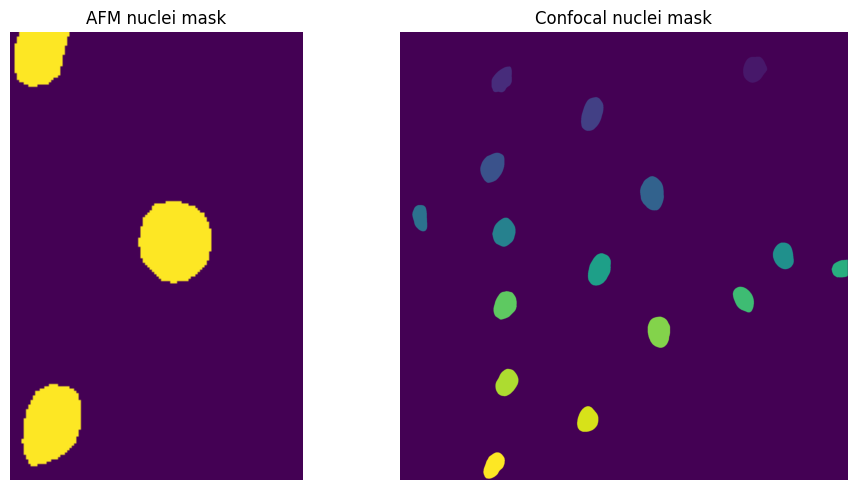

In [3]:

conf_feat = tifffile.imread('data/DAPI_SUM_49-85_flipped_rotated_seg.tif').astype(float)
afm_feat = tifffile.imread('data/AFM_mask_polygon_3nuc.tif').astype(float)

cam_m_px_X,cam_m_px_Y = 0.1083e-06,0.1083e-06
afm_m_px_X , afm_m_px_Y = 0.5097e-06,0.5097e-06


dwn_scale = cam_m_px_X / afm_m_px_X 
up_scale = 1/dwn_scale      

#downscaling the confocal image
conf_feat_dwn = rescale(conf_feat, dwn_scale, anti_aliasing=True)
H, W = afm_feat.shape
yy, xx = np.mgrid[:H, :W]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(afm_feat)
axes[0].set_title("AFM nuclei mask")

axes[1].imshow(conf_feat)
axes[1].set_title("Confocal nuclei mask")


for ax in axes:
    ax.axis("off")

fig.tight_layout()
plt.show()

## Rotational cross correlation

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


match rotation score: 0.8015186607837298
rotation angle: 0.6000000000000041
top-left (row, col) in rescaled optical: 87 200


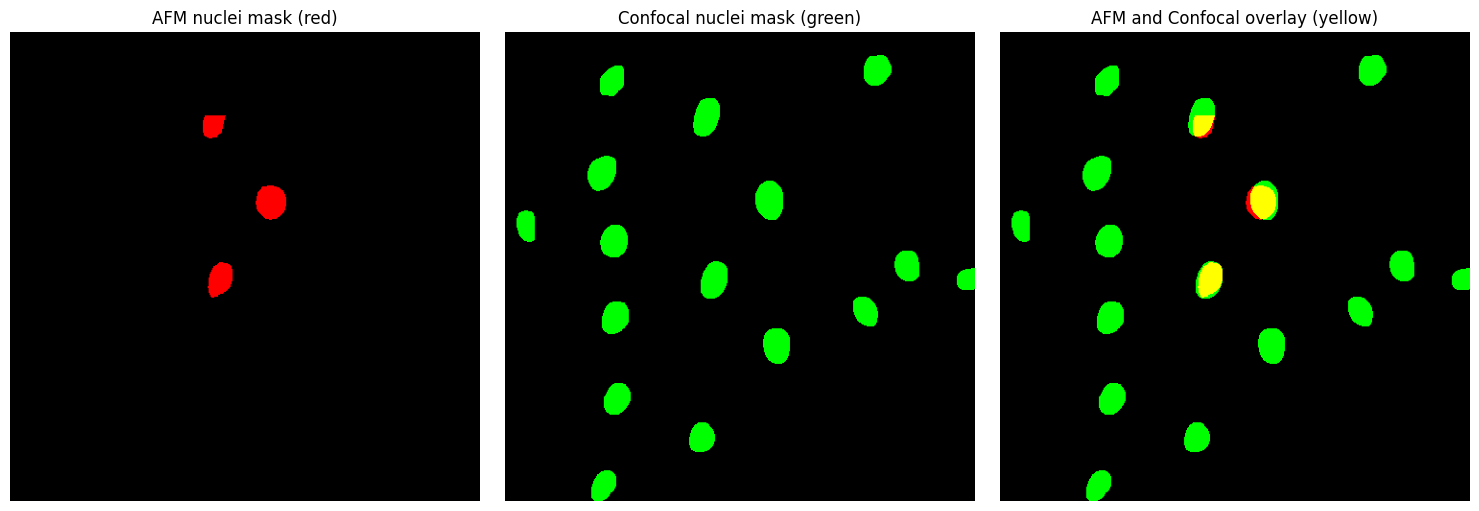

In [4]:
shift_coord_rot = [0, 0]

theta, [x, y], score = max_rotational_cross_corr(
    conf_feat_dwn.astype(float), afm_feat.astype(float), angle_range=(-4, 4), angle_step=0.2)

rotated_afm_feat = ndimage.rotate(afm_feat, theta, reshape=False, order=0)

result_rot = match_template(conf_feat_dwn.astype(float), rotated_afm_feat.astype(float))
row, col = np.unravel_index(np.argmax(result_rot), result_rot.shape)
score =  result_rot[row, col]
shift_coord_rot[0] = row
shift_coord_rot[1] = col

print("match rotation score:", score)
print("rotation angle:", theta)
print("top-left (row, col) in rescaled optical:",  shift_coord_rot[0], shift_coord_rot[1])
rgb,r,g = do_overlay(rotated_afm_feat, conf_feat_dwn, shift_coord_rot)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(r)
axes[0].set_title("AFM nuclei mask (red)")

axes[1].imshow(g)
axes[1].set_title("Confocal nuclei mask (green)")

axes[2].imshow(rgb)
axes[2].set_title("AFM and Confocal overlay (yellow)")

for ax in axes:
    ax.axis("off")

fig.tight_layout()
plt.show()


## Constructing transformation matrix

In [5]:
x, y = float(shift_coord_rot[0]), float(shift_coord_rot[1])
conf_shape = np.shape(conf_feat)
# AFM pixel (0,0) centre
p0 = np.array(rot_ds_to_conf(y , x , theta, up_scale, conf_shape))
p1 = np.array(rot_ds_to_conf(y +1,
              x, theta, up_scale, conf_shape))  # AFM pixel (1,0)
p2 = np.array(rot_ds_to_conf(y , x +1, theta, up_scale, conf_shape))  # AFM pixel (0,1)




M = np.array([[p1[0] - p0[0], p2[0] - p0[0], p0[0]],
              [p1[1] - p0[1], p2[1] - p0[1], p0[1]],
              [0, 0, 1]])


## Refining transformation matrix through an affine transformation

In [6]:

def warp_conf_to_afm(img, m):
    return ndi.map_coordinates(img, [m[1, 0] * xx + m[1, 1] * yy + m[1, 2],
                                     m[0, 0] * xx + m[0, 1] * yy + m[0, 2]], order=1)


def params_to_M(p):
    return np.array([[p[0], p[1], p[2]], [p[3], p[4], p[5]], [0, 0, 1]])


def cost(p):
    m = params_to_M(p)
    a = np.corrcoef(warp_conf_to_afm(conf_feat, m), afm_feat)[0, 1]
    return -(a)

x0 = M[:2].ravel()
print("score before refine:", -cost(x0))
res = optimize.minimize(cost, x0, method="Powell", options=dict(
xtol=1e-3, ftol=1e-6, maxiter=20000))
M = params_to_M(res.x)
print("score after  refine:", -res.fun)
ex, ey = M[:2, 0], M[:2, 1]
print("AFM x-axis: %.3f um/px at %.2f deg" %
      (np.linalg.norm(ex) * cam_m_px_Y, np.degrees(np.arctan2(ex[1], ex[0]))))
print("AFM y-axis: %.3f um/px at %.2f deg" %
      (np.linalg.norm(ey) * cam_m_px_Y, np.degrees(np.arctan2(ey[1], ey[0]))))
print("shear (deviation of the y-axis from perpendicular): %.2f deg" %
      (np.degrees(np.arctan2(ey[1], ey[0]) - np.arctan2(ex[1], ex[0])) - 90))



score before refine: 0.9788380467445597


/Users/yogehs/miniconda3/envs/yourenvname/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/yogehs/miniconda3/envs/yourenvname/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


score after  refine: 1.0
AFM x-axis: 0.000 um/px at -0.91 deg
AFM y-axis: 0.000 um/px at 100.88 deg
shear (deviation of the y-axis from perpendicular): 11.80 deg


## Transforming the the AFM image into the confocal coordinate space

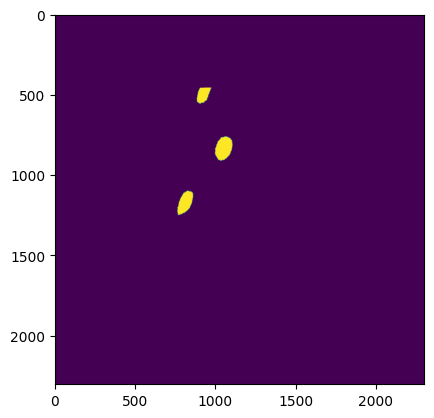

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


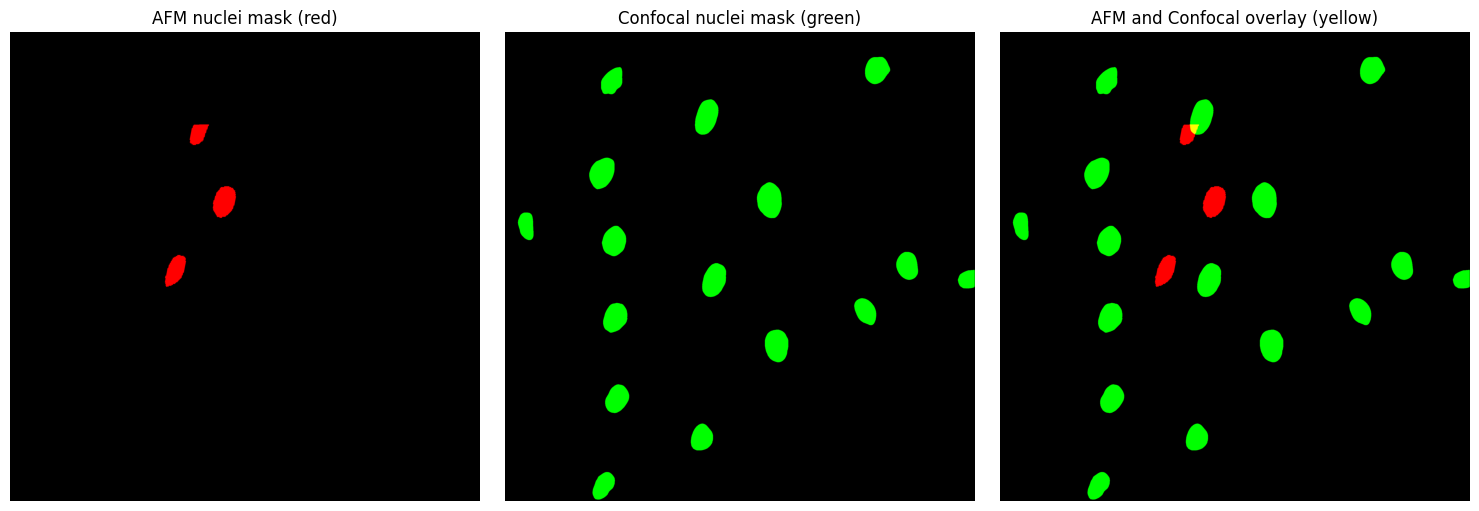

In [7]:

afm_in_confocal = afm_img_to_confocal_frame(M, afm_feat, conf_shape, label='mask')
rgb,r,g = do_overlay(afm_in_confocal, conf_feat, [0,0],mask_bool=True)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(r)
axes[0].set_title("AFM nuclei mask (red)")

axes[1].imshow(g)
axes[1].set_title("Confocal nuclei mask (green)")

axes[2].imshow(rgb)
axes[2].set_title("AFM and Confocal overlay (yellow)")

for ax in axes:
    ax.axis("off")

fig.tight_layout()
plt.show()